# Lab: Data Visualization and Visual Thinking

The U.S. Bureau of Transportation Statistics collects information about scheduled domestic flights. In this lab, you will use the ideas from **Data Visualization and Visual Thinking** to examine a documented sample of 5,000 completed, non-diverted flights from May 2026.


## Learning goals

By the end of this lab, you should be able to:

- load and inspect a CSV file as a Pandas DataFrame;
- distinguish Pandas data types from quantitative and categorical feature types;
- check for missing values;
- create and label a histogram and a bar chart;
- describe a distribution by its typical values, range, and skew;
- use `.describe()` to check estimates made from a histogram;
- explain how histogram bins and axis scales affect a figure; and
- identify conclusions that can and cannot be supported by a sample; and
- find a documented dataset, audit every feature, and interpret its quantitative and categorical distributions.


## Using AI tools responsibly

You may use an AI tool to ask questions, debug code, or receive feedback. You are still responsible for understanding every part of your submission and checking suggestions against your notebook's output. At the end of the lab, disclose whether you used an AI tool and how you evaluated its advice.


## Dataset

The [U.S. Bureau of Transportation Statistics (BTS) Reporting Carrier On-Time Performance data](https://www.transtats.bts.gov/DL_SelectFields.aspx?QO_fu146_anzr=b0-gvzr&gnoyr_VQ=FGJ) contains 611,735 reported domestic flight records for May 2026. Completed, non-diverted flights with recorded values for all five selected features were eligible for this lab. Canceled flights, diverted flights, and records missing any selected feature were excluded before the sample was drawn.

The dataset is a reproducible random sample of 5,000 eligible flights. Each observation represents one completed, non-diverted domestic flight in that sample. Because incomplete records were removed before sampling, finding no missing values in the dataset does not mean that the original BTS data had no missing values. Conclusions from this sample describe the eligible flights and should not automatically be generalized to canceled or diverted flights.

| Feature | Description |
| --- | --- |
| `airline` | Airline that reported the flight |
| `origin_city` | Departure city |
| `destination_city` | Arrival city |
| `distance_miles` | Nonstop flight distance in miles |
| `arrival_delay_minutes` | Minutes between scheduled and actual arrival; negative values mean the flight arrived early |


## Load and preview the data

Import Pandas using the conventional alias `pd`. Read `data/bts_flights_may_2026_sample.csv` into a DataFrame named `flights`.


In [2]:
import pandas as pd
flights = pd.read_csv("data/bts_flights_may_2026_sample.csv")

Display the first five rows of the DataFrame.


In [3]:
flights.head()


,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
0,Alaska Airlines,"Anchorage, AK","Chicago, IL",2846,65
1,Alaska Airlines,"Anchorage, AK","Cordova, AK",160,-1
2,Alaska Airlines,"Anchorage, AK","Fairbanks, AK",261,-18
3,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-21
4,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-14


Display the last five rows of the DataFrame.


In [4]:
flights.tail()


,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
4995,United Airlines,"West Palm Beach/Palm Beach, FL","Chicago, IL",1144,0
4996,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-22
4997,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-29
4998,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,-26
4999,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,7


## Inspect the DataFrame

Display a summary of the DataFrame that includes the feature names, the number of non-missing values, and the Pandas data types.


In [5]:
flights.info()


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   airline                5000 non-null   str  
 1   origin_city            5000 non-null   str  
 2   destination_city       5000 non-null   str  
 3   distance_miles         5000 non-null   int64
 4   arrival_delay_minutes  5000 non-null   int64
dtypes: int64(2), str(3)
memory usage: 399.5 KB


**How many observations are in the DataFrame?**

Your answer:


Count the missing values in every feature.


In [6]:
flights.isna().sum()


airline                  0
origin_city              0
destination_city         0
distance_miles           0
arrival_delay_minutes    0
dtype: int64

## Classify the features

A **quantitative feature** records an amount or measurement for which arithmetic is meaningful. A **categorical feature** assigns observations to groups or labels.


**Complete the table with the Pandas data type, feature type, and number of missing values for each feature. Use `.info()` and `.isnull().sum()`; enter 0 when no values are missing.**

| Feature | Pandas data type | Feature type | Number of missing values |
| --- | --- | --- | ---: |
| `airline` |  |  |  |
| `origin_city` |  |  |  |
| `destination_city` |  |  |  |
| `distance_miles` |  |  |  |
| `arrival_delay_minutes` |  |  |  |


## Which destination city is most common in the sample?

Calculate and display the frequency of each destination city. Save the result as `destination_counts`.


In [7]:
destination_counts = flights["destination_city"].value_counts()
destination_counts


destination_city
Chicago, IL                      296
Atlanta, GA                      222
Dallas/Fort Worth, TX            210
Denver, CO                       209
Washington, DC                   165
                                ... 
Watertown, SD                      1
Cedar City, UT                     1
Sun Valley/Hailey/Ketchum, ID      1
Carlsbad, CA                       1
Redding, CA                        1
Name: count, Length: 238, dtype: int64

Import `matplotlib.pyplot` using the conventional alias `plt`. Use `.head(10)` on `destination_counts` to select the ten most frequent destination cities, then create a bar chart. Give the figure a descriptive title and label both axes.


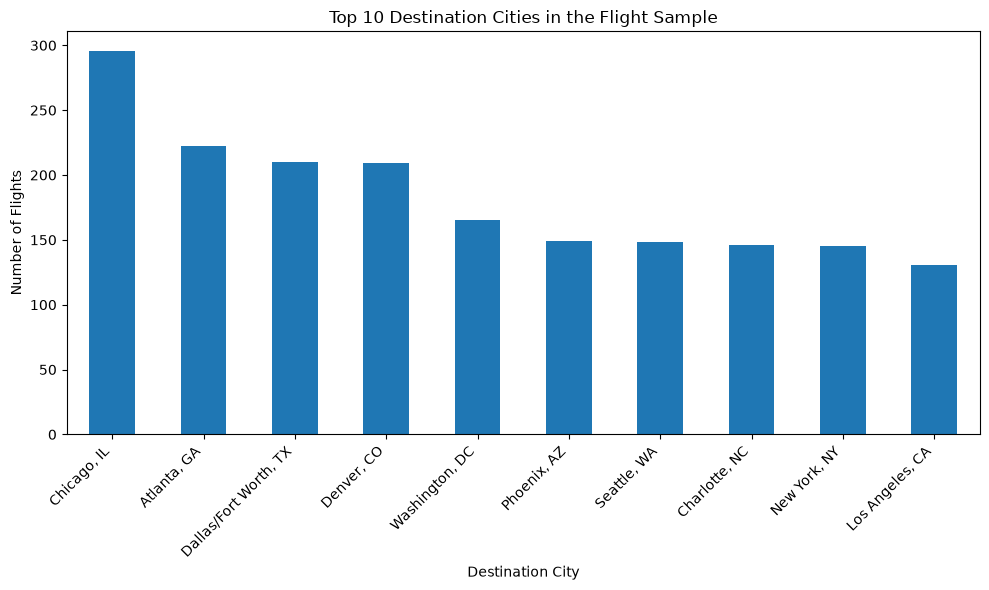

In [8]:
import matplotlib.pyplot as plt

destination_counts.head(10).plot(kind="bar", figsize=(10, 6))
plt.title("Top 10 Destination Cities in the Flight Sample")
plt.xlabel("Destination City")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Which destination city is most common in the sample?**

Your answer: Chicago, IL


## What was the distribution of arrival delays?

Negative values represent early arrivals, zero represents an on-time arrival, and positive values represent late arrivals.

Create a histogram of `arrival_delay_minutes` using the default number of bins. Give the figure a descriptive title and label both axes.


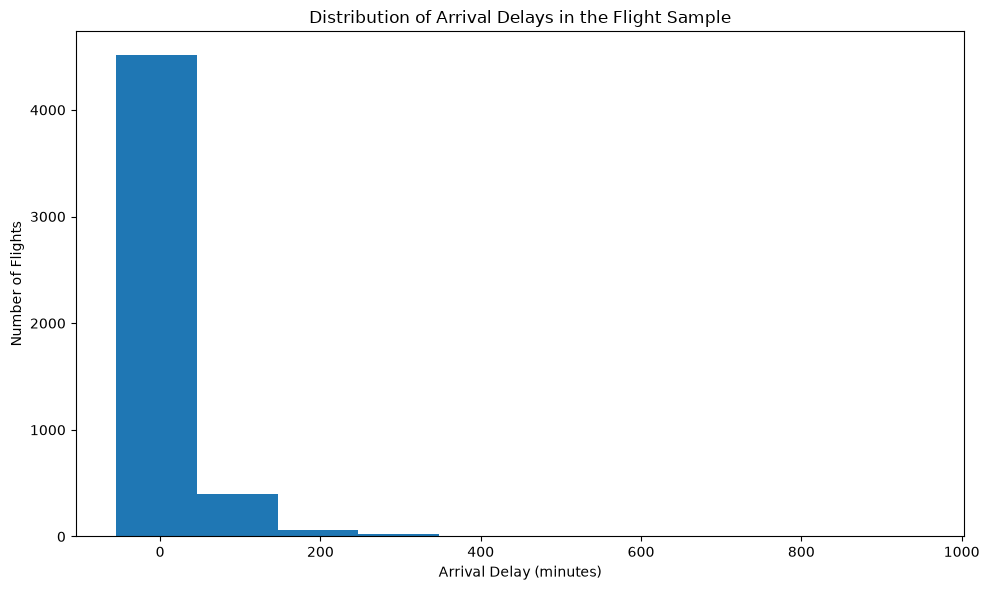

In [9]:
flights["arrival_delay_minutes"].plot(kind="hist", figsize=(10, 6))
plt.title("Distribution of Arrival Delays in the Flight Sample")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.show()


**Approximately what arrival-delay value appears most common?**

Your answer:Approximately 0 minutes, based on the tallest histogram bar


**What is the approximate range from the smallest to the largest arrival-delay value?**

Your answer:“Arrival delays range from approximately −50 to 950 minutes.


**Does the arrival-delay distribution appear symmetric or skewed?**

Your answer:


Display a numerical summary of `arrival_delay_minutes`.


In [10]:
flights["arrival_delay_minutes"].describe()


count    5000.000000
mean        6.098800
std        48.335493
min       -55.000000
25%       -16.000000
50%        -6.000000
75%        10.000000
max       953.000000
Name: arrival_delay_minutes, dtype: float64

Calculate and display the exact mode of `arrival_delay_minutes` using `.mode()`.


In [11]:
flights["arrival_delay_minutes"].mode()


0   -8
Name: arrival_delay_minutes, dtype: int64

**How closely did the calculated mode match the most common value you estimated from the histogram?**

Your answer:The exact mode was −8 minutes, close to my estimate of 0 minutes. The histogram groups values into intervals, so it does not show the exact mode.


**How closely did the minimum and maximum from `.describe()` match the range you estimated from the histogram?**

Your answer:The minimum was −55 minutes and the maximum was 953 minutes. These were close to my estimated range of −50 to 950 minutes.


**Is the mean greater than, less than, or approximately equal to the median?**

Your answer:The mean of about 6.10 minutes is greater than the median of −6 minutes.


**How is the relationship between the mean and median connected to the histogram's shape?**

Your answer:The distribution is right-skewed. A few very large delays pull the mean upward more than the median.


## Applying the principles: histogram bins

Re-create the arrival-delay histogram using exactly 5 bins.


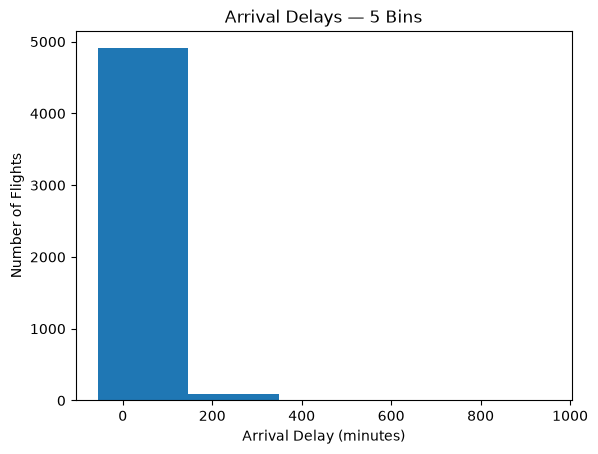

In [12]:
flights["arrival_delay_minutes"].plot(kind="hist", bins=5)
plt.title("Arrival Delays — 5 Bins")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")
plt.show()


Re-create the arrival-delay histogram using exactly 25 bins.


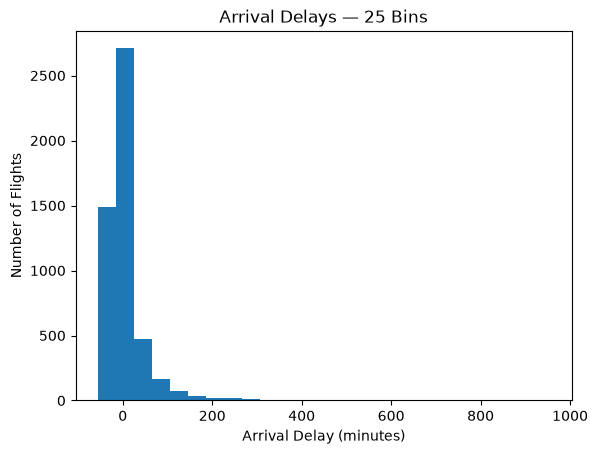

In [13]:
flights["arrival_delay_minutes"].plot(kind="hist", bins=25)
plt.title("Arrival Delays — 25 Bins")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")
plt.show()


**What changed when the number of bins was reduced to 5?**

Your answer:The bars became wider, grouping more delay values together and hiding detail. The distribution still appeared right-skewed.


**What changed when the number of bins was increased to 25?**

Your answer:The bars became narrower, showing more detail about where arrival delays were concentrated. The long right tail remained


**Which bin setting communicates the distribution most clearly?**

Your answer:I would choose 25 bins because it shows more detail near the most common arrival times while still showing the right-skewed shape.


## Applying the principles: a misleading vertical axis

Run both cells below and compare the figures.


In [ ]:
top_destinations = destination_counts.head(5)
top_destinations.plot(kind="bar")
plt.title("Five Most Frequent Destination Cities in the Sample")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


In [ ]:
top_destinations.plot(kind="bar")
plt.ylim(top_destinations.min() - 10, top_destinations.max() + 10)
plt.title("Five Most Frequent Destination Cities with a Truncated Vertical Axis")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


**How does the truncated axis change the apparent differences among the destination cities?**

Your answer:The truncated axis exaggerates the differences, making cities with higher counts look much larger because the vertical axis starts above zero.


**Which chart communicates the counts more honestly?**

Your answer:The first chart communicates the counts more honestly because its vertical axis starts at zero, so bar lengths reflect the relative flight counts accurately.


## Is this sample representative?

Review the dataset description at the top of the lab before answering these questions.


**What time period is represented by the source data?**

Your answer: 2026


**Which flights were eligible to be included in the sample?**

Your answer:Completed, non-diverted domestic flights with recorded values for all five selected features were eligible. Canceled flights, diverted flights, and records missing any selected feature were excluded.


**Which flights and records were excluded before the sample was selected?**

Your answer:Canceled flights, diverted flights, and records missing any of the five selected features were excluded.


**Does finding no missing values in the sample prove that the original BTS data had no missing values?**

Your answer:No. Incomplete records were removed before sampling, so the sample cannot establish whether the original data had missing values.


**Why should conclusions from this sample not automatically be generalized to canceled or diverted flights?**

Your answer:Those flights were excluded from the sample and may have different characteristics from completed, non-diverted flights.


## Choosing a chart

Choose a histogram, bar chart, or pie chart for each question. Use the question and number of categories to justify your choice.


**Which chart would you use to show the frequency of each airline?**

Your answer:A bar chart, because airlines are categories and bar heights make their flight counts easy to compare, even with many airlines.


**Which chart would you use to show what proportion of sampled flights were early, on time, and delayed? Use arrival delays below 0, equal to 0, and above 0 minutes, respectively.**

Your answer:A pie chart, because there are only three categories and together they account for all sampled flights. Each slice shows a proportion of the whole.


**Which chart would you use to show the distribution of flight distances?**

Your answer:A histogram, because distance is quantitative. Grouping distances into intervals shows where flights are concentrated and the distribution’s shape.


## Explore a dataset of your own

Apply the same inspection and visualization process to a different dataset that interests you.

### 1. Find and describe your dataset

Start with [Kaggle Datasets](https://www.kaggle.com/datasets), the [UCI Machine Learning Repository](https://archive.ics.uci.edu/), or [Data.gov](https://catalog.data.gov/). You can also search a city or state open-data portal. Search for a topic you enjoy, such as sports, music, animals, transportation, or the environment.

Choose a manageable CSV file with a data dictionary (or equivalent feature documentation), at least one quantitative feature, and at least one categorical feature with a manageable number of categories. Use a different dataset from the flights and penguins already used in class. Save the file in this notebook's `data` folder.

Read the data dictionary before choosing your features. In a short paragraph, describe the dataset's subject, what one row represents, and its time period and geographic coverage if documented. Include its title, publisher or creator, a direct link to the dataset, and a link to the data dictionary. State when information is not documented instead of guessing.


**Dataset description and source links:**

Your answer:I chose the Spotify Tracks Dataset published by Maharshi Pandya. Each row represents a Spotify track entry with information such as its artist, song title, popularity, duration, and audio features. The creator collected the data using Spotify’s Web API. The documentation does not specify a collection time period or geographic coverage.

Dataset and column descriptions: https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset

CSV: https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset/resolve/main/dataset.csv


### 2. Load the data and describe every feature

Load your CSV into a new DataFrame with a descriptive name ending in `_df`, such as `movies_df`, `weather_df`, or `animals_df`. Choose a name that describes your dataset and use it consistently throughout your analysis. Display its first five rows, shape, `.info()`, and `.isnull().sum()` to inspect its features, storage types, and missing values. Use a relative path so your notebook can run on another computer.


In [14]:
music_df = pd.read_csv("data/dataset.csv")

display(music_df.head())
print("Rows and columns:", music_df.shape)
music_df.info()
display(music_df.isnull().sum())

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


Rows and columns: (114000, 21)
<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

Complete the table below with **one row for every feature** in your dataset. Add as many rows as needed. Use the data dictionary to summarize what each feature means, including units or category-code meanings where relevant.

- **Data type:** quantitative or categorical; identify identifiers and date/time features explicitly when appropriate. A numeric identifier is not a quantitative measurement.
- **Data storage type:** the actual Pandas dtype shown by `.info()` or `.dtypes`, such as `int64`, `float64`, `object`, `str`, or `datetime64[ns]`.
- **Missing values:** the number reported for that feature, including 0 when there are none. Count missing values before removing records. If the dictionary defines special missing codes, such as -999 or "Unknown", explain how you handle those codes and make sure the counts reflect that decision.


| Feature | Description from the data dictionary (including units/codes) | Data type | Data storage type | Number of missing values |
| --- | --- | --- | --- | ---: |
|  |  |  |  |  |

**Missing-value codes or other data preparation, if applicable:**

Your answer Missing-value counts were calculated before removing any records. Artists, album name, and track name each have one missing value; all other columns have zero. No records have been removed. The key code −1 means an undetected key and is retained as a special category. For explicit lyrics, False combines non-explicit and unknown status, so these cannot be distinguished. The exported index is not used as a measurement


### 3. Visualize one quantitative feature

Choose one quantitative measurement and create an appropriate visualization of its distribution, such as a histogram. Include a descriptive title, a horizontal-axis label naming the feature and its units, and a vertical-axis label explaining what the heights represent. Explain any excluded missing values or other filtering. Do not use an ID number as your quantitative feature.


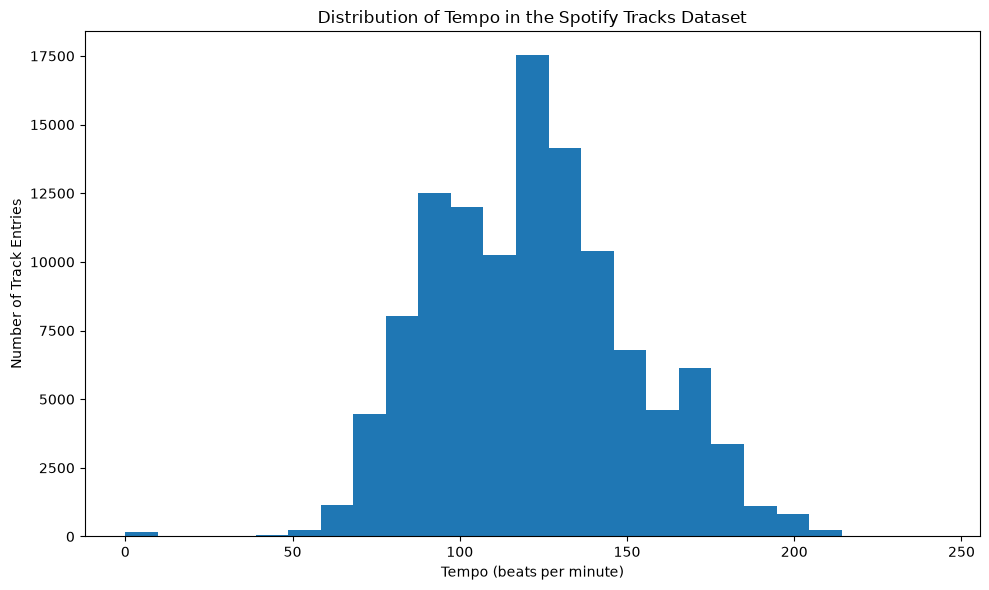

In [15]:
import matplotlib.pyplot as plt

music_df["tempo"].plot(kind="hist", bins=25, figsize=(10, 6))
plt.title("Distribution of Tempo in the Spotify Tracks Dataset")
plt.xlabel("Tempo (beats per minute)")
plt.ylabel("Number of Track Entries")
plt.tight_layout()
plt.show()


**Which feature did you choose, and why is this chart appropriate?**

Your answer:I chose tempo, measured in beats per minute (BPM). A histogram is appropriate because tempo is quantitative, and grouping values into intervals shows its distribution. No records were filtered out, and tempo has no missing values.

**In at least one complete sentence, describe what the figure tells you about this feature.** Refer to a visible pattern such as typical values, range, shape, or unusual observations, using values and units where possible. Describe the observations in your dataset without assuming they represent a larger population.

Your interpretation:Most track entries in this dataset have tempos between approximately 80 and 150 BPM, with the tallest bar around 120 BPM. Relatively few entries have tempos below 60 BPM or above 200 BPM. These findings describe this dataset, rather than all music.


### 4. Visualize one categorical feature

Choose a categorical feature and create an appropriate visualization of its distribution. A bar chart of category counts is a good choice; use `.value_counts()` to obtain numeric bar heights from text labels. Include a descriptive title and labels identifying the categories and counts or percentages on the axes. If you choose a pie chart for a small number of categories, label the slices and their shares instead of axes. Explain any excluded missing values or categories, and identify the denominator if you use percentages.


mode
Major    72681
Minor    41319
Name: count, dtype: int64

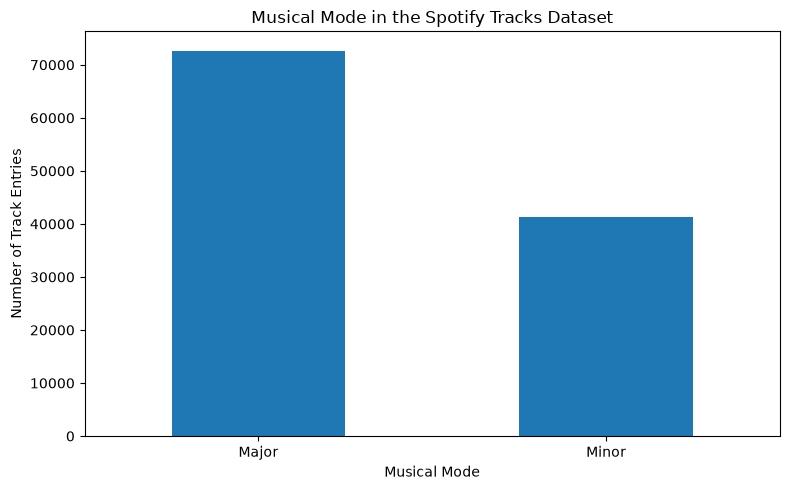

In [16]:
mode_counts = music_df["mode"].map({0: "Minor", 1: "Major"}).value_counts()
display(mode_counts)

mode_counts.plot(kind="bar", figsize=(8, 5))
plt.title("Musical Mode in the Spotify Tracks Dataset")
plt.xlabel("Musical Mode")
plt.ylabel("Number of Track Entries")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Which feature did you choose, and why is this chart appropriate?**

Your answer:I chose musical mode, where 0 represents minor and 1 represents major. Although stored as numbers, these values represent categories. A bar chart makes their counts easy to compare. Mode has no missing values, and no records were excludedS

**In at least one complete sentence, describe what the figure tells you about this feature.** Identify a meaningful pattern, such as the most or least common category or a difference in counts or shares. Support the interpretation with evidence visible in your figure.

Your interpretation:Major mode is more common in this dataset, with 72,681 track entries compared with 41,319 in minor mode. Major-mode entries account for approximately 63.8% of the 114,000 entries. This describes the dataset and does not necessarily represent all Spotify tracks.


## Reflect on AI assistance

Complete one of the following statements.

**If you used an AI tool:**

- Tool used:ChatGPT/Codex
- What I asked it to help with:I had to have help setting up VScode and Jupyter labs I also had help opening the files correctly. I had ChatGPT rewrite my written answers to correct punctuations, grammer and flow. Codex helped me correct Python code errors before plugging them into jupyter to run.
- One suggestion I checked against my code, chart, or output:I compared the suggested interpretation of musical mode with my output, which showed 72,681 major-mode entries and 41,319 minor-mode entries.
- What I accepted, modified, or rejected—and why:I accepted the rewrite of my written ansers simply because i am horrible with punctuations and tend to ramble instead of stating my points, Modified code corrections to fix errors when running. why? I am not super confident in python so anyting i would try i checked against codex to make sure it would even run with or without errors.

**If you did not use an AI tool:**

- I did not use an AI tool for this assignment.
- One resource or troubleshooting strategy I used instead was:


Your response:


## Submission checklist

- All code cells run from top to bottom without errors.
- The destination-city bar chart has a descriptive title and labeled axes.
- The default, 5-bin, and 25-bin arrival-delay histograms are included and labeled.
- Both vertical-axis demonstrations are included.
- Every question has one response in its own answer cell.
- The sample questions are answered using the dataset documentation.
- The chosen dataset and its data dictionary are linked and described.
- The feature table includes a description, data type, storage type, and missing-value count for every feature.
- One quantitative and one categorical feature have appropriate labeled visualizations and at least one sentence of interpretation each.
- The chosen CSV is included in the `data` folder with the submitted notebook, and relative paths work.
- The AI-use reflection is complete and honest.
